# Clasificación de imágenes con Vision Transformers (ViT)
### Piedra, papel o tijera: fine-tuning de un ViT preentrenado con HuggingFace

**Universidad de Santiago de Chile (USACH)**  
Diplomado de Inteligencia artificial aplicada a la industria tecnológica  
Reelaborado por Diego Fischer

*Basado en material original de [Domingo Mery](https://domingomery.ing.puc.cl/) (Departamento de Ciencia de la Computación, Pontificia Universidad Católica de Chile), con una adaptación previa de Javier Tramon.*

---

En este cuaderno vamos a construir un clasificador de imágenes que distingue las tres señas del juego **piedra, papel o tijera**. Pero el objetivo real no es el juego: es entender los **Vision Transformers (ViT)** y, sobre todo, **por qué partimos de un modelo preentrenado en lugar de entrenar uno desde cero**.


El flujo:

1. Entender qué es un ViT y por qué usar uno preentrenado.
2. Descargar el dataset desde Kaggle y prepararlo.
3. Cargar el ViT preentrenado y **adaptarle la cabeza** a nuestras 3 clases.
4. Hacer *fine-tuning* y evaluar.
5. Probar el modelo en imágenes individuales.

---

## ¿Qué es un Vision Transformer?

Los *Transformers* nacieron en el procesamiento de lenguaje natural (son la 'T' de GPT y BERT). Su ingrediente clave es la **atención** (*self-attention*): cada palabra de una frase puede "mirar" a todas las demás para entender el contexto.

El **Vision Transformer** (Dosovitskiy et al., 2020) tuvo una idea audaz: *¿y si tratamos una imagen como si fuera una frase?* El procedimiento es directo:

1. **Cortar la imagen en parches.** La imagen de 224×224 se divide en una grilla de parches cuadrados de 16×16 píxeles (de ahí el nombre `patch16`). Eso da 14×14 = 196 parches.
2. **Convertir cada parche en un vector** (*token*), tal como una palabra se convierte en un vector en NLP. Cada parche es ahora una "palabra visual".
3. **Agregar información de posición** (*positional embeddings*), para que el modelo sepa de qué lugar de la imagen venía cada parche, y un token especial `[CLS]` que resumirá la imagen completa.
4. **Pasar todo por capas de atención.** Aquí está la diferencia profunda con las redes convolucionales (CNN): mientras una CNN construye su comprensión de lo local a lo global de a poco, la atención permite que **cualquier parche se relacione con cualquier otro desde la primera capa**. El modelo puede conectar la punta de un dedo con la muñeca al otro lado de la imagen de inmediato.
5. **Clasificar** a partir del token `[CLS]` final, con una capa lineal.

El modelo que usaremos se llama `google/vit-base-patch16-224-in21k`. Descifremos el nombre, porque cada parte importa:

- **base**: tamaño mediano del modelo (~86 millones de parámetros).
- **patch16**: parches de 16×16 píxeles.
- **224**: espera imágenes de 224×224 píxeles.
- **in21k**: fue **preentrenado en ImageNet-21k**, un dataset de ~14 millones de imágenes y 21.843 clases.

Ese último punto — el preentrenamiento — es el corazón de todo lo que sigue.

---

## ¿Por qué partir de un ViT preentrenado? (la pregunta central)

Podríamos crear un ViT con pesos aleatorios y entrenarlo desde cero con nuestras imágenes de piedra-papel-tijera. **Sería un desastre.** Entender por qué es entender el *transfer learning*.

### 1. Los ViT son "hambrientos de datos"

Las CNN traen incorporados ciertos supuestos sobre las imágenes (que los píxeles vecinos se relacionan, que un objeto es el mismo si se desplaza). A esos supuestos se les llama *sesgos inductivos*, y le ahorran datos al modelo. **Los ViT casi no tienen esos sesgos**: son más flexibles, pero por lo mismo necesitan ver *muchísimas* imágenes para descubrir por su cuenta cómo funciona el mundo visual. Entrenados desde cero con pocos datos, rinden **peor** que una CNN. Con millones de imágenes, en cambio, los superan.

### 2. Nosotros tenemos pocos datos

Nuestro dataset tiene unos pocos miles de imágenes. Eso es **nada** para entrenar un ViT desde cero (que querría millones). Si lo intentáramos, el modelo memorizaría el puñado de ejemplos sin aprender nada general, y fallaría con cualquier mano nueva.

### 3. El modelo preentrenado ya sabe "ver"

Aquí está la magia. Al preentrenarse sobre 14 millones de imágenes, el ViT ya aprendió representaciones visuales **generales y ricas**: bordes, texturas, formas, partes de objetos, contornos de manos. Ese conocimiento **no es específico de ImageNet** — sirve para casi cualquier tarea visual, incluida la nuestra.

La analogía: es como contratar a alguien que ya sabe ver, leer y reconocer objetos, y solo enseñarle un juego nuevo. No tienes que enseñarle a ver desde el nacimiento. Reutilizamos ese "sistema visual" ya formado y solo lo especializamos.

### 4. ¿Qué hacemos entonces sobre el ViT preentrenado?

Tres cosas, que son el núcleo práctico de este cuaderno:

- **Le cambiamos la cabeza.** El ViT preentrenado termina en una capa que predice 21.843 clases de ImageNet. A nosotros no nos sirve: necesitamos **3** salidas (piedra, papel, tijera). Así que descartamos esa capa final y la reemplazamos por una nueva, del tamaño correcto, inicializada de cero.
- **Lo afinamos suavemente** (*fine-tuning*). Seguimos entrenando, pero con una tasa de aprendizaje **muy baja**, para ajustar apenas las representaciones al dominio de las manos sin destruir lo que ya sabía.
- **Le damos la entrada en el formato que espera.** Redimensionamos a 224×224 y normalizamos los píxeles con la **misma** media y desviación con que fue preentrenado, para que sus características reconozcan lo que ven.

Cada una de estas decisiones aparecerá explícita en el código. Empecemos.

---

## Fase 1 — Instalación y entorno

Necesitamos dos paquetes que no vienen por defecto en Colab: `transformers` (la librería de HuggingFace que nos da el ViT) y `kagglehub` (para descargar el dataset). El resto (PyTorch, torchvision) ya está.

> **Activa la GPU** antes de entrenar: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*. Un ViT en CPU es lentísimo.

In [ ]:
!pip install -q -U transformers kagglehub scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 69.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 83.7 MB/s eta 0:00:00


In [ ]:
import os
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split, Dataset
import matplotlib.pyplot as plt

from transformers import ViTForImageClassification, ViTImageProcessor

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', device)
print('¿GPU disponible?:', torch.cuda.is_available())

Dispositivo: cuda
¿GPU disponible?: True


## Fase 2 — Descargar y explorar el dataset

Usamos `kagglehub`, que descarga el dataset y nos devuelve la ruta local donde quedó. La primera vez tarda un poco (descarga los archivos); luego queda en caché.

In [ ]:
import kagglehub

# Descarga la última versión del dataset (piedra-papel-tijera)
path = kagglehub.dataset_download('sanikamal/rock-paper-scissors-dataset')
print('Dataset descargado en:', path)

100%|██████████| 452M/452M [00:21<00:00, 22.0MB/s]

Extracting files...


Dataset descargado en: /root/.cache/kagglehub/datasets/sanikamal/rock-paper-scissors-dataset/versions/1


### Explorar la estructura

Los datasets del mundo real vienen en estructuras de carpetas muy variadas. Antes de cargar nada, **miremos qué nos llegó**. Este hábito evita el error más común: asumir una estructura que no es la que tenemos.

Imprimimos el árbol de carpetas (hasta cierta profundidad) y contamos imágenes por carpeta.

In [ ]:
EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}

def contar_imagenes(carpeta):
    return sum(1 for f in Path(carpeta).iterdir()
               if f.is_file() and f.suffix.lower() in EXTS)

# Árbol resumido
raiz = Path(path)
for d in sorted(raiz.rglob('*')):
    if d.is_dir():
        prof = len(d.relative_to(raiz).parts)
        if prof <= 3:
            n = contar_imagenes(d)
            marca = f'  <- {n} imágenes' if n else ''
            print('   ' * prof + '📁 ' + d.name + marca)

   📁 Rock-Paper-Scissors
      📁 test
         📁 paper  <- 124 imágenes
         📁 rock  <- 124 imágenes
         📁 scissors  <- 124 imágenes
      📁 train
         📁 paper  <- 840 imágenes
         📁 rock  <- 840 imágenes
         📁 scissors  <- 840 imágenes
      📁 validation  <- 33 imágenes
   📁 rock-paper-scissors
      📁 Rock-Paper-Scissors
         📁 test
         📁 train
         📁 validation  <- 33 imágenes


### Detectar automáticamente train / val / test

En vez de escribir rutas a mano (que se romperían si el dataset cambia), **detectamos** las carpetas con formato *ImageFolder* — es decir, carpetas que contienen subcarpetas-de-clase llenas de imágenes (`.../rock/`, `.../paper/`, `.../scissors/`).

Luego las clasificamos por su nombre en `train`, `val`/`validation` y `test`. Si el dataset no trae alguna de esas particiones, la **creamos nosotros** dividiendo los datos disponibles. Así el cuaderno funciona sin importar cómo venga empaquetado.

In [ ]:
def es_imagefolder(d):
    """True si 'd' contiene >=2 subcarpetas y al menos 2 tienen imágenes."""
    subdirs = [x for x in d.iterdir() if x.is_dir()]
    if len(subdirs) < 2:
        return False
    con_img = sum(1 for s in subdirs if contar_imagenes(s) > 0)
    return con_img >= 2

# Buscar todas las carpetas tipo ImageFolder
roots = [d for d in raiz.rglob('*') if d.is_dir() and es_imagefolder(d)]

# Quedarnos con los roots 'de más alto nivel' (evitar duplicados anidados)
roots = [r for r in roots if not any(r != o and o in r.parents for o in roots)]

# Clasificar por nombre
splits = {}
for r in roots:
    nombre = r.name.lower()
    if 'train' in nombre:
        splits['train'] = r
    elif 'val' in nombre:        # cubre 'val' y 'validation'
        splits['val'] = r
    elif 'test' in nombre:
        splits['test'] = r

# Si no reconocimos por nombre pero hay un único root, ese es todo el dataset
if not splits and len(roots) == 1:
    splits['completo'] = roots[0]

print('Carpetas ImageFolder detectadas:')
for k, v in splits.items():
    print(f'  {k:10s} -> {v}   ({sum(contar_imagenes(s) for s in v.iterdir() if s.is_dir())} imágenes)')

Carpetas ImageFolder detectadas:
  train      -> /root/.cache/kagglehub/datasets/sanikamal/rock-paper-scissors-dataset/versions/1/rock-paper-scissors/Rock-Paper-Scissors/train   (2520 imágenes)
  test       -> /root/.cache/kagglehub/datasets/sanikamal/rock-paper-scissors-dataset/versions/1/rock-paper-scissors/Rock-Paper-Scissors/test   (372 imágenes)


## Fase 3 — Preparar los datos: transformaciones y particiones

### Por qué estas transformaciones (y no otras)

Aquí hay una decisión crítica ligada a que el modelo es **preentrenado**. El ViT no acepta cualquier imagen: espera exactamente lo que vio durante su preentrenamiento. Por eso preguntamos al *procesador oficial* del modelo cuál es el tamaño y la normalización correctos, y los replicamos.

- **Redimensionar a 224×224:** el tamaño con que se entrenó. Otro tamaño rompería la grilla de parches.
- **Normalizar con la media y desviación del preentrenamiento:** el modelo aprendió sus características esperando píxeles en cierto rango estadístico. Si le pasamos píxeles con otra escala, sus filtros "ven mal". Esto es sutil pero importante: **normalizar distinto al preentrenamiento degrada el modelo sin dar ningún error**.
- **Aumento de datos (*augmentation*) solo en entrenamiento:** un volteo horizontal aleatorio genera variedad gratis (una mano de "piedra" espejada sigue siendo piedra) y ayuda a no sobreajustar. En validación y test **no** aumentamos, porque ahí queremos medir el rendimiento sobre la imagen tal cual.

In [ ]:
MODELO_ID = 'google/vit-base-patch16-224-in21k'

# El procesador oficial nos dice el tamaño y la normalización que espera el ViT
procesador = ViTImageProcessor.from_pretrained(MODELO_ID)
media, desv = procesador.image_mean, procesador.image_std
tam = procesador.size.get('height', procesador.size.get('shortest_edge', 224))

print(f'Tamaño esperado : {tam}x{tam}')
print(f'Media (mean)    : {media}')
print(f'Desv. (std)     : {desv}')

# Transformaciones de entrenamiento (con aumento) y de evaluación (sin aumento)
tf_train = transforms.Compose([
    transforms.Resize((tam, tam)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=media, std=desv),
])

tf_eval = transforms.Compose([
    transforms.Resize((tam, tam)),
    transforms.ToTensor(),
    transforms.Normalize(mean=media, std=desv),
])

print('\nTransformaciones listas.')

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Tamaño esperado : 224x224
Media (mean)    : (0.5, 0.5, 0.5)
Desv. (std)     : (0.5, 0.5, 0.5)

Transformaciones listas.


### Construir los tres conjuntos

Manejamos ambos casos con una función: si el dataset ya trae `train/val/test`, los usamos directamente (cada uno con su transformación). Si no, cargamos todo y lo dividimos **70% / 15% / 15%** de forma reproducible (semilla fija).

El pequeño envoltorio `ConTransformacion` nos permite aplicar transformaciones distintas a cada partición aun cuando provienen de una misma división.

In [ ]:
class ConTransformacion(Dataset):
    """Aplica una transformación a un subconjunto que entrega imágenes PIL."""
    def __init__(self, subset, tf):
        self.subset = subset
        self.tf = tf
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, i):
        img, label = self.subset[i]   # img es PIL (transform=None en la base)
        return self.tf(img), label


if {'train', 'val', 'test'}.issubset(splits):
    # El dataset ya viene particionado
    train_ds = torchvision.datasets.ImageFolder(splits['train'], transform=tf_train)
    val_ds   = torchvision.datasets.ImageFolder(splits['val'],   transform=tf_eval)
    test_ds  = torchvision.datasets.ImageFolder(splits['test'],  transform=tf_eval)
    clases = train_ds.classes

else:
    # Tomamos el root disponible (train si existe, si no el 'completo') y dividimos
    root = splits.get('train', splits.get('completo', roots[0]))
    base = torchvision.datasets.ImageFolder(root, transform=None)  # entrega PIL
    clases = base.classes
    n = len(base)
    n_tr = int(0.70 * n)
    n_va = int(0.15 * n)
    n_te = n - n_tr - n_va
    g = torch.Generator().manual_seed(42)
    sub_tr, sub_va, sub_te = random_split(base, [n_tr, n_va, n_te], generator=g)
    train_ds = ConTransformacion(sub_tr, tf_train)
    val_ds   = ConTransformacion(sub_va, tf_eval)
    test_ds  = ConTransformacion(sub_te, tf_eval)

NUM_CLASES = len(clases)
print('Clases        :', clases)
print('N° de clases  :', NUM_CLASES)
print(f'Train / Val / Test : {len(train_ds)} / {len(val_ds)} / {len(test_ds)}')

Clases        : ['paper', 'rock', 'scissors']
N° de clases  : 3
Train / Val / Test : 1764 / 378 / 378


### Mirar algunas imágenes (con sus etiquetas)

Siempre conviene ver los datos con los propios ojos antes de entrenar. Como las imágenes ya están **normalizadas** (para el ViT), para mostrarlas hay que **des-normalizarlas** primero — si no, se verían con colores extraños. Este detalle es una consecuencia directa de haber normalizado para el modelo preentrenado.

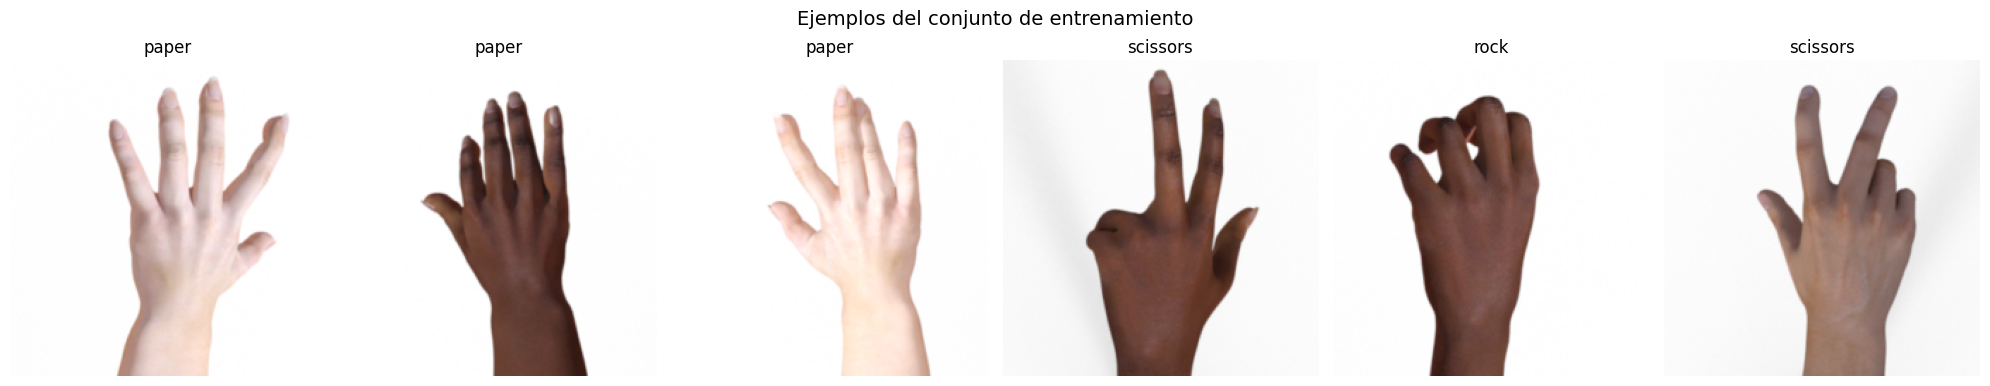

In [ ]:
# Des-normalización inversa para poder visualizar
media_t = torch.tensor(media).view(3, 1, 1)
desv_t = torch.tensor(desv).view(3, 1, 1)

def a_visualizable(tensor_img):
    img = tensor_img * desv_t + media_t      # deshace la normalización
    return img.permute(1, 2, 0).clamp(0, 1).numpy()

fig, axes = plt.subplots(1, 6, figsize=(20, 4))
for ax in axes:
    i = np.random.randint(len(train_ds))
    img, label = train_ds[i]
    ax.imshow(a_visualizable(img))
    ax.set_title(clases[label])
    ax.axis('off')
plt.suptitle('Ejemplos del conjunto de entrenamiento', fontsize=14)
plt.tight_layout()
plt.show()

## Fase 4 — Cargar el ViT preentrenado y adaptarle la cabeza

**Esta es la celda más importante del cuaderno.** En una sola llamada hacemos lo que describimos en la introducción: traer el ViT con todo su conocimiento visual y reemplazarle la cabeza de clasificación.

Las tres claves de `from_pretrained`:

- **`MODELO_ID`**: descarga los pesos preentrenados (el "sistema visual" ya formado).
- **`num_labels=NUM_CLASES`**: le pedimos una cabeza de **3** salidas en vez de las 21.843 originales.
- **`ignore_mismatched_sizes=True`**: esta es la instrucción que le dice "la nueva cabeza no calza en tamaño con la vieja, y está bien: **descártala y crea una nueva**". Sin esto, HuggingFace se negaría a cargar porque los tamaños no coinciden. El resto del modelo (los parches, la atención, todo el cuerpo que sabe ver) se conserva intacto.

También le pasamos el diccionario `id2label` para que el modelo "sepa" que su salida 0 es tal clase, la 1 tal otra, etc. — útil al momento de interpretar predicciones.

In [ ]:
modelo = ViTForImageClassification.from_pretrained(
    MODELO_ID,
    num_labels=NUM_CLASES,
    ignore_mismatched_sizes=True,          # descarta la cabeza vieja, crea una nueva
    id2label={i: c for i, c in enumerate(clases)},
    label2id={c: i for i, c in enumerate(clases)},
)
modelo.to(device)

# Veamos cuántos parámetros tiene y confirmemos el tamaño de la nueva cabeza
total = sum(p.numel() for p in modelo.parameters())
print(f'Parámetros totales del ViT : {total/1e6:.1f} millones')
print(f'Cabeza de clasificación    : {modelo.classifier}')

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/6 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
encoder.layer.{0...11}.attention.output.dense.weight    | UNEXPECTED | 
encoder.layer.{0...11}.intermediate.dense.bias          | UNEXPECTED | 
encoder.layer.{0...11}.output.dense.weight              | UNEXPECTED | 
pooler.dense.weight                                     | UNEXPECTED | 
encoder.layer.{0...11}.attention.attention.value.weight | UNEXPECTED | 
encoder.layer.{0...11}.output.dense.bias                | UNEXPECTED | 
encoder.layer.{0...11}.layernorm_after.weight           | UNEXPECTED | 
encoder.layer.{0...11}.attention.attention.key.weight   | UNEXPECTED | 
encoder.layer.{0...11}.attention.output.dense.bias      | UNEXPECTED | 
encoder.layer.{0...11}.layernorm_before.weight          | UNEXPECTED | 
encoder.layer.{0...11}.attention.attention.

Parámetros totales del ViT : 85.8 millones
Cabeza de clasificación    : Linear(in_features=768, out_features=3, bias=True)


> **Fíjate en la advertencia** que imprime HuggingFace (algo como *"some weights were newly initialized: classifier.weight, classifier.bias"*). **No es un error, es exactamente lo que queremos:** confirma que el cuerpo del ViT se cargó con los pesos preentrenados y que solo la cabeza (`classifier`) nació nueva y aleatoria, lista para aprender nuestras 3 clases.

> **Variante de fine-tuning:** aquí entrenaremos **todo** el modelo (cuerpo + cabeza) con una tasa de aprendizaje baja. Una alternativa más conservadora es *congelar* el cuerpo (`requires_grad=False`) y entrenar solo la cabeza — más rápido y con menos riesgo de sobreajuste cuando hay muy pocos datos. Para este dataset, afinar todo suave funciona bien.

## Fase 5 — Entrenar (fine-tuning)

Ahora el bucle de entrenamiento. Conceptos ligados al hecho de partir preentrenados:

- **Tasa de aprendizaje muy baja (`2e-5`):** este número pequeño es deliberado. No queremos re-enseñarle a ver al modelo, solo **afinarlo**. Una tasa alta daría pasos grandes que borrarían las valiosas características preentrenadas — un fenómeno llamado *olvido catastrófico*. Fine-tuning = empujoncitos suaves.
- **Optimizador AdamW:** el estándar para afinar Transformers.
- **Pérdida Cross-Entropy:** la típica para clasificación multiclase.
- **Early stopping:** si la métrica de validación deja de mejorar, paramos, para no malgastar cómputo ni empezar a sobreajustar.

Guardamos los pesos de la mejor época según la *accuracy* de validación.

In [ ]:
EPOCAS      = 8      # pocas bastan gracias al preentrenamiento; sube si quieres
BATCH       = 32     # baja a 16 si te quedas sin memoria de GPU
LR          = 2e-5   # tasa baja: fine-tuning suave
PACIENCIA   = 3      # épocas sin mejorar antes de detener

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2)

optimizador = torch.optim.AdamW(modelo.parameters(), lr=LR)
criterio = nn.CrossEntropyLoss()


def evaluar(loader):
    """Recorre un loader y retorna (pérdida promedio, accuracy)."""
    modelo.eval()
    suma_perdida, correctos, total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            logits = modelo(pixel_values=imgs).logits
            suma_perdida += criterio(logits, labels).item() * imgs.size(0)
            correctos += (logits.argmax(1) == labels).sum().item()
            total += imgs.size(0)
    return suma_perdida / total, correctos / total

In [ ]:
hist = {'train_loss': [], 'val_loss': [], 'val_acc': []}
mejor_acc = 0.0
sin_mejora = 0

for epoca in range(EPOCAS):
    modelo.train()
    suma = 0.0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)

        logits = modelo(pixel_values=imgs).logits   # forward
        perdida = criterio(logits, labels)

        optimizador.zero_grad()
        perdida.backward()                           # gradientes
        optimizador.step()                           # actualiza pesos
        suma += perdida.item() * imgs.size(0)

    train_loss = suma / len(train_ds)
    val_loss, val_acc = evaluar(val_loader)
    hist['train_loss'].append(train_loss)
    hist['val_loss'].append(val_loss)
    hist['val_acc'].append(val_acc)
    print(f'Época {epoca+1:2d}/{EPOCAS}  '
          f'train_loss={train_loss:.4f}  '
          f'val_loss={val_loss:.4f}  val_acc={val_acc:.4f}')

    # Guardar el mejor modelo y controlar early stopping
    if val_acc > mejor_acc:
        mejor_acc = val_acc
        torch.save(modelo.state_dict(), 'mejor_vit.pth')
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            print(f'Sin mejora en {PACIENCIA} épocas: detenemos (early stopping).')
            break

print(f'\nMejor accuracy de validación: {mejor_acc:.4f}')

Época  1/8  train_loss=1.0683  val_loss=1.0259  val_acc=0.3519
Época  2/8  train_loss=0.7199  val_loss=0.4061  val_acc=0.8730
Época  3/8  train_loss=0.3349  val_loss=0.3733  val_acc=0.8730
Época  4/8  train_loss=0.1888  val_loss=0.2443  val_acc=0.9127
Época  5/8  train_loss=0.1316  val_loss=0.1401  val_acc=0.9709
Época  6/8  train_loss=0.1256  val_loss=0.0919  val_acc=0.9762
Época  7/8  train_loss=0.0684  val_loss=0.0755  val_acc=0.9815
Época  8/8  train_loss=0.0627  val_loss=0.4614  val_acc=0.8386

Mejor accuracy de validación: 0.9815


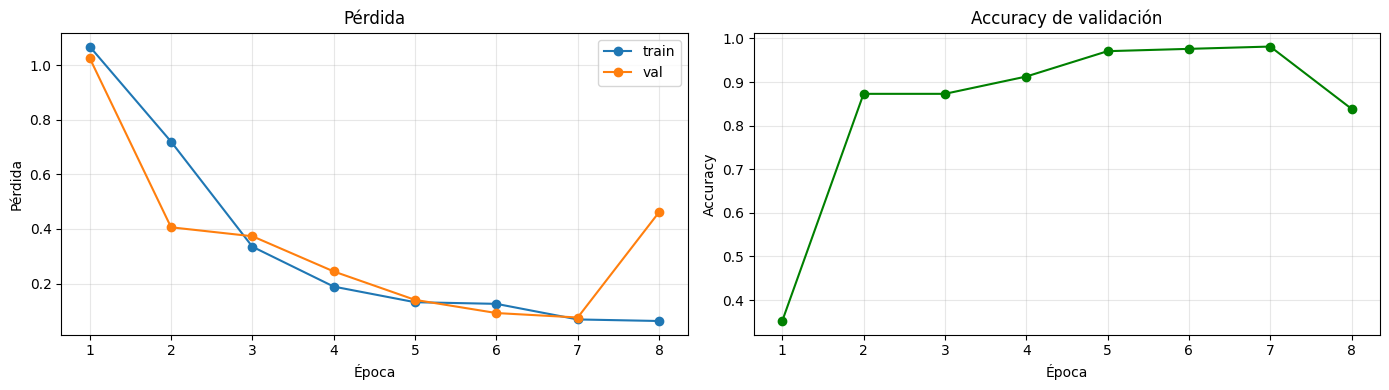

In [ ]:
# Curvas de entrenamiento
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
e = range(1, len(hist['train_loss']) + 1)
ax1.plot(e, hist['train_loss'], marker='o', label='train')
ax1.plot(e, hist['val_loss'], marker='o', label='val')
ax1.set_xlabel('Época'); ax1.set_ylabel('Pérdida'); ax1.set_title('Pérdida')
ax1.legend(); ax1.grid(alpha=0.3)
ax2.plot(e, hist['val_acc'], marker='o', color='green')
ax2.set_xlabel('Época'); ax2.set_ylabel('Accuracy'); ax2.set_title('Accuracy de validación')
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Fase 6 — Evaluar el modelo entrenado

Cargamos los mejores pesos guardados y medimos la *accuracy* en los tres conjuntos. Comparar train vs. val vs. test nos dice si el modelo **generaliza** o si está **sobreajustado** (accuracy de train muy alta y de test baja sería mala señal).

In [ ]:
modelo.load_state_dict(torch.load('mejor_vit.pth', map_location=device))

_, acc_train = evaluar(train_loader)
_, acc_val   = evaluar(val_loader)
_, acc_test  = evaluar(test_loader)

print(f'Accuracy train : {acc_train:.4f}  ({len(train_ds)} imágenes)')
print(f'Accuracy val   : {acc_val:.4f}  ({len(val_ds)} imágenes)')
print(f'Accuracy test  : {acc_test:.4f}  ({len(test_ds)} imágenes)')

Accuracy train : 0.9875  (1764 imágenes)
Accuracy val   : 0.9815  (378 imágenes)
Accuracy test  : 0.9735  (378 imágenes)


### Matriz de confusión

La *accuracy* resume todo en un número, pero esconde **qué** confunde el modelo. La matriz de confusión muestra, para cada clase real, cómo se repartieron las predicciones. La diagonal son los aciertos; todo lo de fuera son errores, y nos dice exactamente qué par de clases se confunde (por ejemplo, si tijera se confunde con papel).

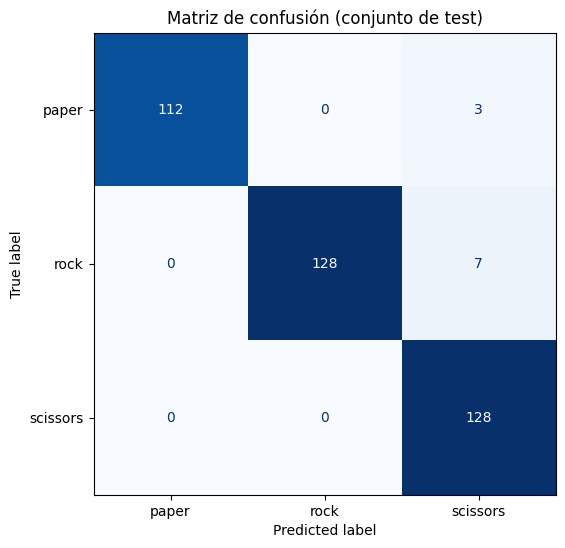

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true, y_pred = [], []
modelo.eval()
with torch.no_grad():
    for imgs, labels in test_loader:
        logits = modelo(pixel_values=imgs.to(device)).logits
        y_pred.extend(logits.argmax(1).cpu().numpy())
        y_true.extend(labels.numpy())

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clases)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.title('Matriz de confusión (conjunto de test)')
plt.show()

## Fase 7 — Probar en imágenes individuales

Finalmente, veamos al modelo trabajar caso a caso: tomamos imágenes de test, las clasificamos y mostramos la predicción junto a la etiqueta real y la confianza (probabilidad tras aplicar *softmax* a los logits).

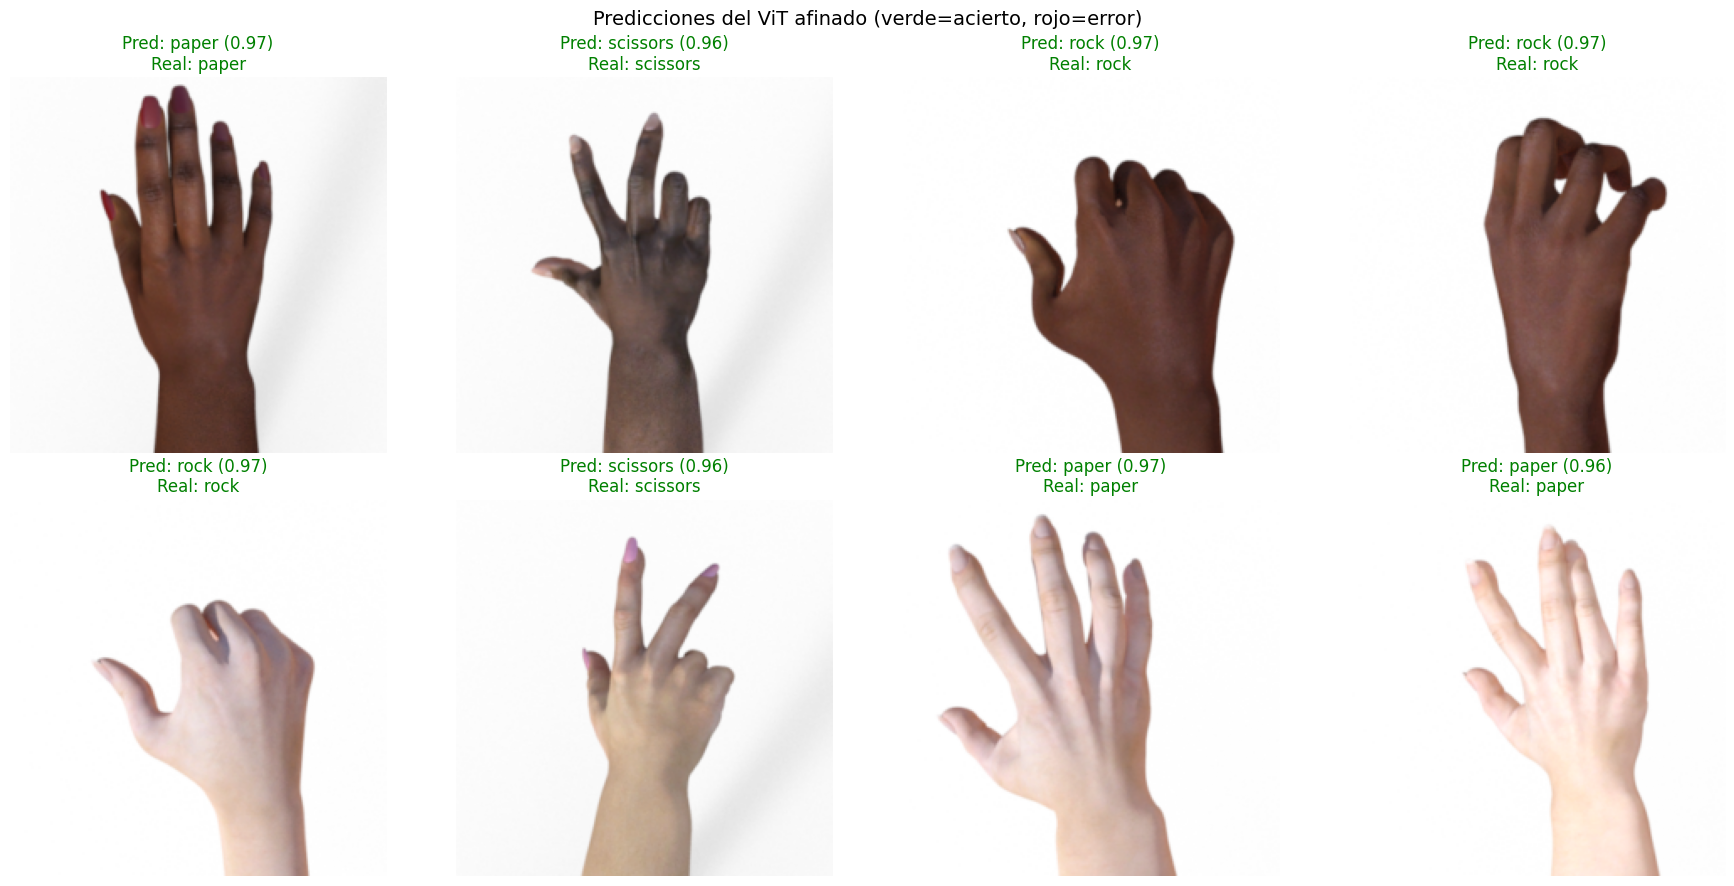

In [ ]:
import torch.nn.functional as F

modelo.eval()
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
with torch.no_grad():
    for ax in axes.ravel():
        i = np.random.randint(len(test_ds))
        img, label = test_ds[i]
        logits = modelo(pixel_values=img.unsqueeze(0).to(device)).logits
        probs = F.softmax(logits, dim=1)[0]
        pred = int(probs.argmax())
        conf = float(probs[pred])

        acierto = (pred == label)
        color = 'green' if acierto else 'red'
        ax.imshow(a_visualizable(img))
        ax.set_title(f'Pred: {clases[pred]} ({conf:.2f})\nReal: {clases[label]}',
                     color=color)
        ax.axis('off')
plt.suptitle('Predicciones del ViT afinado (verde=acierto, rojo=error)', fontsize=14)
plt.tight_layout()
plt.show()

---
## Licencia y créditos

[![Licencia Creative Commons](https://i.creativecommons.org/l/by/4.0/88x31.png)](https://creativecommons.org/licenses/by/4.0/deed.es)

Este cuaderno está licenciado bajo una [Licencia Creative Commons Atribución 4.0 Internacional (CC BY 4.0)](https://creativecommons.org/licenses/by/4.0/deed.es). Puede compartirse y adaptarse, incluso con fines comerciales, siempre que se reconozca la autoría de forma adecuada.

**Reelaboración y explicaciones:** Diego Fischer — Universidad de Santiago de Chile (USACH).  
**Material original:** Domingo Mery (Pontificia Universidad Católica de Chile), con una adaptación previa de Javier Tramon.  
**Dataset:** *Rock-Paper-Scissors* (sanikamal, Kaggle).  
**Modelo:** `google/vit-base-patch16-224-in21k` vía HuggingFace Transformers.